In [1]:
import cobra
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
import os
from scipy import stats
from statsmodels.stats.multitest import  multipletests
import operator
plt.rcParams['figure.figsize'] = [11, 7]



In [2]:
MODEL_PATH = "models/iJN678_std_aminoacids.json"  # <-- EDIT: path to your genome-scale model (SBML/JSON/MAT)
model = cobra.io.load_json_model(MODEL_PATH)

Set parameter Username
Set parameter LicenseID to value 2866505
Academic license - for non-commercial use only - expires 2027-09-22


/tmp/ipykernel_25150/3391924605.py:136: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("coolwarm", 2)


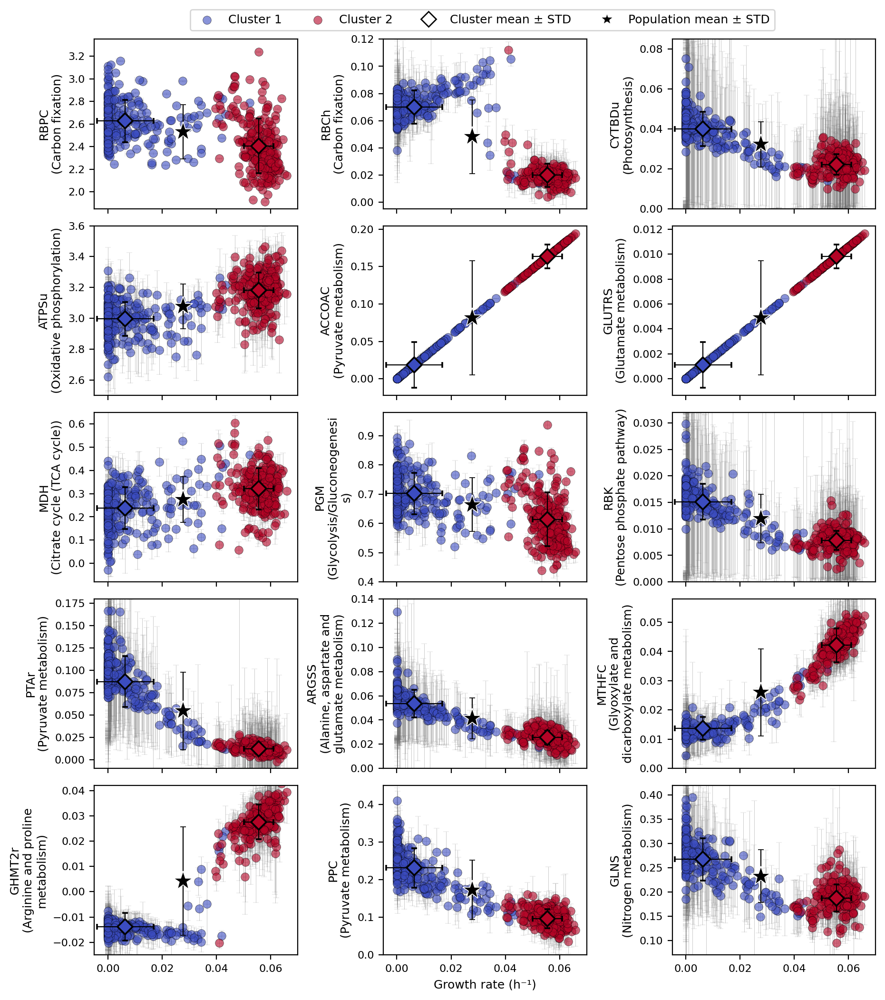

In [22]:

from matplotlib import cm
from matplotlib.lines import Line2D

means2 = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat', sep='\t', index_col=0)
stds2 = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat', sep='\t', index_col=0)

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_4ox.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS_4ox.dat', sep='\t')

indexes = means2.index
#indexes = []
#for file in os.listdir('results_new/RuBisCo/'):
#    if 'cell' in file: 
#        i = int(file.split('cell')[-1].split('.')[0])
#        indexes.append(i)
indexes = sorted(indexes)

means_toy = means_toy.loc[indexes]
stds_toy = stds_toy.loc[indexes]


import textwrap

SUBSYSTEM_WRAP_WIDTH = 25  # <-- EDIT: characters per line before the subsystem name wraps

def get_subsystem(reaction):
    '''Return a clean subsystem string for a cobra Reaction (robust to str/list/frozenset).'''
    sub = reaction.subsystem
    if sub is None:
        return "Unknown"
    if isinstance(sub, (list, set, frozenset, tuple)):
        sub = "; ".join(sorted(sub)) if len(sub) else "Unknown"
    sub = str(sub).strip()
    return sub if sub else "Unknown"


def reaction_label(rxn_id):
    """'{rxn_id}\n(subsystem, wrapped across lines if long)'"""
    try:
        subsystem = get_subsystem(model.reactions.get_by_id(rxn_id))
    except KeyError:
        subsystem = "Unknown"
    wrapped = "\n".join(textwrap.wrap(subsystem, SUBSYSTEM_WRAP_WIDTH)) or "Unknown"
    return f"{rxn_id}\n({wrapped})"
    

# ---------------------------------------------------------------------------
# Group cells by the two clusters in clusters_4to12h_N_NEW.dat instead of by
# acetate exchange direction.
# ---------------------------------------------------------------------------
clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')

CLUSTER_COL = 'cluster'  # column holds 0 / 1

clusters = clusters.loc[indexes]  # align to the same cell order used for means2 / means_toy

cluster_values = sorted(clusters[CLUSTER_COL].unique())  # -> [0, 1]
assert len(cluster_values) == 2, f"Expected exactly 2 clusters, found: {cluster_values}"

# <-- EDIT: give the two clusters more descriptive names if you like
CLUSTER_LABELS = {cluster_values[0]: f"Cluster 1",
                   cluster_values[1]: f"Cluster 2"}

mask_cluster_a = clusters[CLUSTER_COL] == cluster_values[0]
mask_cluster_b = clusters[CLUSTER_COL] == cluster_values[1]

group_keys = [cluster_values[0], cluster_values[1]]
group_masks = [mask_cluster_a, mask_cluster_b]

groups = {k: means2[m] for k, m in zip(group_keys, group_masks)}
groups_toy = {k: means_toy[m] for k, m in zip(group_keys, group_masks)}
groups_std = {k: stds2[m] for k, m in zip(group_keys, group_masks)}
groups_std_toy = {k: stds_toy[m] for k, m in zip(group_keys, group_masks)}

# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
reactions = [
    "RBPC",
    "RBCh",
    "CYTBDu",
    "ATPSu",
    "ACCOAC",
    "GLUTRS",
    "MDH",
    "PGM",
  #  "GAPDi_nadp",
    "RBK",
    "PTAr",
    "ARGSS",
    #"EX_glu__L_e",

    "MTHFC",
    "GHMT2r",
   # "GLUDy",
    "PPC",
    "GLNS",

]

# per-reaction y-limits (from your original code)
ylims = {
    "PHBS_syn": (-0.001, 0.0075),
    "RBPC": (1.85, 3.35),
    "RBCh": (-0.005, 0.12),
    "MDH": (-0.08, 0.65),
    "PGM": (-0.98, -0.4),
    "GAPDi_nadp": (3.35, 6.4),
    'GLUDy': (-0.25, 0.08),
    "GLNS": (0.07, 0.42),
    "ARGSS": (0, 0.14),
    'PPC': (0, 0.45),
    "PTAr": (-0.01, 0.18),
    'EX_glu__L_e': (-0.023, 0.024),
    'GHMT2r': (-0.025, 0.042),
    'CYTBDu': (0,0.085),
    'MTHFC': (0,0.058),
    'RBK': (0,0.032),
    "ATPSu": (2.5, 3.6),
}

ncols = 3
nrows = math.ceil(len(reactions) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(10.6, 2.5 * nrows),
    dpi=200, sharex=True,
)
fig.subplots_adjust(wspace=0.42, hspace=0.1)

axes = np.array(axes).flatten()

# 2 discrete colors, one per cluster (pulled from the extremes of coolwarm_r,
# same family as the original 4-color version)
cmap = cm.get_cmap("coolwarm", 2)
group_colors = [cmap(i) for i in range(2)]
# how to summarize the spread of the cluster average marker:
# "std"  -> spread of individual cells within the cluster (population std)
# "sem"  -> standard error of the mean (std / sqrt(n)), tighter, describes
#           how precisely the cluster mean itself is known
AVERAGE_ERROR = "std"  # <-- EDIT: "std" or "sem"

for ax, r in zip(axes, reactions):

    for i, key in enumerate(group_keys):
        df = groups[key]
        x = df['BIOMASS_Ec_SynMixo']
        xerr = groups_std_toy[key]['growth']

        if r == "RBPC_RBCh":
            y = df["RBPC"] / df["RBCh"]
            yerr = None
        else:
            y = df[r]
            yerr = groups_std[key][r]

        sign = -1 if r in ('EX_glu__L_e', 'RPE', 'PGM') else 1

        sc = ax.scatter(
            x, sign * y,
            s=40,
            color=group_colors[i],
            edgecolor='black',
            linewidth=0.3,
            label=CLUSTER_LABELS[key],
            alpha=0.6,
        )
        ax.errorbar(
            x, sign * y,
            xerr=xerr,
            yerr=yerr,
            fmt='none',
            ecolor='dimgrey',
            elinewidth=0.25,
            capsize=2, capthick=0.15,
            alpha=0.5, zorder=-1,
        )

        # --- cluster average, plotted on top as a bold diamond ---
        n = len(x)
        avg_x, avg_y = x.mean(), sign * y.mean()
        if AVERAGE_ERROR == "sem":
            avg_xerr = x.std(ddof=1) / np.sqrt(n)
            avg_yerr = y.std(ddof=1) / np.sqrt(n)
        else:
            avg_xerr = x.std(ddof=1)
            avg_yerr = y.std(ddof=1)

        ax.errorbar(
            avg_x, avg_y,
            xerr=avg_xerr, yerr=avg_yerr,
            fmt='D',
            ms=8,
            mfc=group_colors[i],
            mec='black',
            mew=1.3,
            ecolor='black',
            elinewidth=0.8,
            capsize=2, capthick=0.8,
            zorder=5,
        )

    # --- population average (all cells, both clusters combined) ---
    x_all = means2['BIOMASS_Ec_SynMixo']
    if r == "RBPC_RBCh":
        y_all = means2["RBPC"] / means2["RBCh"]
    else:
        y_all = means2[r]
    sign = -1 if r in ('EX_glu__L_e', 'RPE', 'PGM') else 1

    n_all = len(x_all)
    avg_x_all, avg_y_all = x_all.mean(), sign * y_all.mean()
    if AVERAGE_ERROR == "sem":
        avg_xerr_all = x_all.std(ddof=1) / np.sqrt(n_all)
        avg_yerr_all = y_all.std(ddof=1) / np.sqrt(n_all)
    else:
        avg_xerr_all = x_all.std(ddof=1)
        avg_yerr_all = y_all.std(ddof=1)

    ax.errorbar(
        avg_x_all, avg_y_all,
        yerr=avg_yerr_all,
        fmt='*',
        ms=15,
        mfc='black',
        mec='white',
        mew=0.6,
        ecolor='black',
        elinewidth=0.8,
        capsize=2, capthick=0.8,
        zorder=6,
    )

    if r in ['GLUDy', 'PPC']:
        ax.set_xlabel('Growth rate (h⁻¹)', fontsize=9)
    ax.set_ylabel(reaction_label(r), fontsize=9)
    ax.tick_params(labelsize=8)

    if ylims.get(r) is not None:
        if r in ('EX_glu__L_e', 'RPE', 'PGM'):
            ax.set_ylim((-ylims[r][1], -ylims[r][0]))
        else:
            ax.set_ylim(*ylims[r])

    ax.set_xlim(-0.005, 0.07)

for ax in axes[len(reactions):]:
    ax.remove()

handles, labels = axes[0].get_legend_handles_labels()
cluster_avg_proxy = Line2D(
    [], [], marker='D', color='black', markerfacecolor='white',
    markeredgecolor='black', markersize=8, linestyle='none',
    label=f"Cluster mean ± {AVERAGE_ERROR.upper()}",
)
population_avg_proxy = Line2D(
    [], [], marker='*', color='black', markerfacecolor='black',
    markeredgecolor='white', markersize=11, linestyle='none', linewidth=0.2,
    label=f"Population mean ± {AVERAGE_ERROR.upper()}",
)

fig.legend(
    handles + [cluster_avg_proxy, population_avg_proxy],
    labels + [cluster_avg_proxy.get_label(), population_avg_proxy.get_label()],
    loc="upper center",
    ncol=4,
    frameon=True,
    fontsize=9,
    bbox_to_anchor=(0.51, 0.91),
)

plt.savefig('scatter_fig5.jpeg', format='jpeg', dpi=200,  bbox_inches='tight')
plt.show()

In [5]:
import numpy as np

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')


means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
#
#indexes = []
#for file in os.listdir('results_new/genome_scale_samples_PEAKS_RuBisCO_4ox/'):
#    if 'cell' in file: 
#        i = int(file.split('cell')[-1].split('.')[0])
#        indexes.append(i)
#indexes = sorted(indexes)
indexes = means2.index

means_toy = means_toy.loc[indexes]
stds_toy = stds_toy.loc[indexes]
means2.index=indexes
stds2.index=indexes


df = means_toy  # replace with your actual df

# split by sign
df_pos = df[df["ac"] > 0].copy()
df_neg = df[df["ac"] < 0].copy()

# define thresholds (within each group)
pos_thresh = df_pos["ac"].median()
neg_thresh = df_neg["ac"].median()

df_pos_2 = means2[df["ac"] > 0].copy()
df_neg_2 = means2[df["ac"] < 0].copy()

# positive groups
df_pos_low = df_pos_2[df_pos["ac"] <= pos_thresh]   # moderate positive
df_pos_high = df_pos_2[df_pos["ac"] > pos_thresh]   # high positive

# negative groups
df_neg_low = df_neg_2[df_neg["ac"] >= neg_thresh]   # moderate negative (closer to 0)
df_neg_high = df_neg_2[df_neg["ac"] < neg_thresh]   # high negative (more extreme)

groups = {
    "pos_moderate": df_pos_low,
    "pos_high": df_pos_high,
    "neg_moderate": df_neg_low,
    "neg_high": df_neg_high
}


subsystems = []
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

excluded = ['Transport', 'Extracellular exchange']
          #'Fructose and mannose metabolism', 'Biotin metabolism', 'Nucleotide sugars metabolism', ]
for r in model.reactions:
    if r.subsystem not in subsystems and r.subsystem not in excluded:
        subsystems.append(r.subsystem)

        

        
        
final_mean_dfs = groups.values()

flux_through_pathway = {}
for s in subsystems:
    flux_through_pathway[s] = []
    for df in final_mean_dfs:
        acids = ['EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e', 'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e']
        acids_c = [model.reactions.get_by_id(r).reactants[0].elements['C'] for r in acids]
        acid_cells = []
        for cell in df.iterrows():
            cell_val = 0
            for i,a in enumerate(acids):
                if cell[1][a]*acids_c[i]<0:
                    cell_val += cell[1][a]*acids_c[i]
            acid_cells.append(cell_val)
        acid = abs(np.mean(acid_cells))
        ##print(acid)
        sum_flux = 0
        for r in df.columns:
            if model.reactions.get_by_id(r).subsystem == s:
                #sum_flux += abs(np.mean(df[r]))/(-np.log(np.mean(df['BIOMASS_Ec_SynMixo'])))#/-(np.mean(df['EX_hco3_e'])+acid))
                sum_flux += abs(np.mean(df[r]))#/abs(np.mean(df['EX_hco3_e'])+np.mean(df['EX_nh4_e']))#-acid))
       # print(sum_flux)
        flux_through_pathway[s].append(sum_flux)
        
final_flux_through_pathway = {}
for s in flux_through_pathway:
    all_0 = True
    for f in flux_through_pathway[s]:
        if f>0: 
            all_0 = False
    if not all_0 and s!='':
        final_flux_through_pathway[s] = flux_through_pathway[s]
        
data_df = pd.DataFrame(final_flux_through_pathway).transpose()
columns = ['Moderate\nuptake', 'High\nuptake', 'Moderate\nproduction', 'High\nproduction']
#columns = [ 'RED', 'GREEN', 'PURPLE',]
data_df.columns = columns

Set parameter Username
Set parameter LicenseID to value 2709761

--------------------------------------------
--------------------------------------------

Academic license - for non-commercial use only - expires 2026-09-17


In [ ]:
import numpy as np
import pandas as pd
import cobra

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')

indexes = means2.index

means_toy = means_toy.loc[indexes]
stds_toy = stds_toy.loc[indexes]
means2.index = indexes
stds2.index = indexes

df = means_toy  # replace with your actual df

# ---------------------------------------------------------------------------
# Instead of 4 threshold-based groups, pick 3 single representative cells
# along the acetate exchange ("ac") axis:
#   - the cell that consumes (uptakes) the most acetate
#   - the cell that produces the most acetate (i.e. consumes the "least")
#   - the cell whose net ac flux is closest to zero
# ---------------------------------------------------------------------------
ac = df["ac"]

idx_lowest_consumer = ac.idxmin()        # most negative ac -> highest uptake
idx_highest_consumer = ac.idxmax()         # most positive ac -> highest production / lowest consumption
idx_zero_flux = ac.abs().idxmin()         # net ac flux closest to 0

print("highest consumer -> cell", idx_highest_consumer, "ac =", ac.loc[idx_highest_consumer])
print("lowest consumer  -> cell", idx_lowest_consumer, "ac =", ac.loc[idx_lowest_consumer])
print("zero flux        -> cell", idx_zero_flux, "ac =", ac.loc[idx_zero_flux])

groups = {
    "highest_consumer": means2.loc[[idx_highest_consumer]],
    "lowest_consumer": means2.loc[[idx_lowest_consumer]],
    "zero_flux": means2.loc[[idx_zero_flux]],
}

subsystems = []
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

excluded = ['Transport', 'Extracellular exchange']
for r in model.reactions:
    if r.subsystem not in subsystems and r.subsystem not in excluded:
        subsystems.append(r.subsystem)

final_mean_dfs = groups.values()

flux_through_pathway = {}
for s in subsystems:
    flux_through_pathway[s] = []
    for df in final_mean_dfs:
        acids = ['EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e', 'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e']
        acids_c = [model.reactions.get_by_id(r).reactants[0].elements['C'] for r in acids]
        acid_cells = []
        for cell in df.iterrows():
            cell_val = 0
            for i, a in enumerate(acids):
                if cell[1][a] * acids_c[i] < 0:
                    cell_val += cell[1][a] * acids_c[i]
            acid_cells.append(cell_val)
        acid = abs(np.mean(acid_cells))

        sum_flux = 0
        for r in df.columns:
            if model.reactions.get_by_id(r).subsystem == s:
                sum_flux += abs(np.mean(df[r]))
        flux_through_pathway[s].append(sum_flux)

final_flux_through_pathway = {}
for s in flux_through_pathway:
    all_0 = True
    for f in flux_through_pathway[s]:
        if f > 0:
            all_0 = False
    if not all_0 and s != '':
        final_flux_through_pathway[s] = flux_through_pathway[s]

data_df = pd.DataFrame(final_flux_through_pathway).transpose()
columns = ['Consumer', 'Producer', 'No organic C\nflux']
data_df.columns = columns

highest consumer -> cell 243 ac = 1.91160372325646
lowest consumer  -> cell 495 ac = -2.135228023617469
zero flux        -> cell 151 ac = -0.0039125068473574


In [6]:
data_df

,Moderate\nuptake,High\nuptake,Moderate\nproduction,High\nproduction
Phenylalanine tyrosine and tryptophan biosynthesis,9.759233e-02,7.060336e-02,1.090896e-01,8.807117e-02
Fatty acid biosynthesis,7.813608e-01,9.032383e-01,1.478518e-01,9.554389e-03
Arginine and proline metabolism,4.553004e+02,4.633413e+02,4.571145e+02,4.664006e+02
Nitrogen metabolism,4.726455e+02,4.790731e+02,4.745815e+02,4.823005e+02
Others,5.948943e-02,5.639808e-02,8.044583e-02,8.481228e-02
Citrate cycle (TCA cycle),1.633233e+00,1.689849e+00,1.649886e+00,1.414761e+00
Riboflavin metabolism,4.958838e-02,5.670890e-02,9.547587e-02,1.058608e-01
Purine metabolism,7.571693e-01,8.136492e-01,8.153082e-01,8.466278e-01
Porphyrin and chlorophyll metabolism,3.686105e-02,4.263590e-02,6.995454e-03,4.519818e-04
Terpenoid backbone biosynthesis,3.979808e-02,4.603307e-02,7.552843e-03,4.880019e-04


[Text(0.5, 0, 'High\nuptake'), Text(1.5, 0, 'Moderate\nuptake'), Text(2.5, 0, 'Moderate\nproduction'), Text(3.5, 0, 'High\nproduction')]


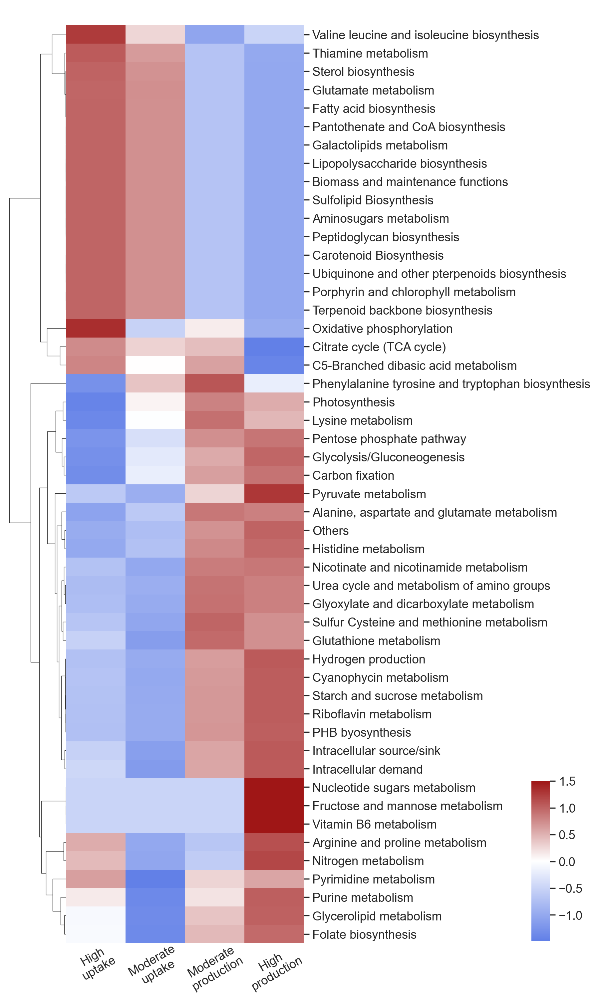

In [12]:
#sns.set(font_scale=1.1)
from matplotlib.colors import LinearSegmentedColormap

# Define custom colors (Start → End)
low_color = "#6280e7"      # Color for low values
mid_color = "#ffffff"     # Neutral midpoint
high_color = "#9f1616"      # Color for high values

# Create diverging colormap
custom_cmap = LinearSegmentedColormap.from_list("diverging_cmap", [low_color, mid_color, high_color])
plt.rcParams['figure.dpi'] = 200
# PREVIOUS MAP : cmap='RdBu_r'


desired_order = ['Consumer', 'No organic C\nflux', 'Producer']
desired_order = ['High\nuptake', 'Moderate\nuptake', 'Moderate\nproduction', 'High\nproduction']


data_df = data_df[desired_order]

g = sns.clustermap(
    data_df,
    figsize=(9.2, 15),
    cmap=custom_cmap,
    cbar_pos=(0.88, 0.05, 0.03, 0.16),
    dendrogram_ratio=(0.2, 0.02),
    z_score=0,
    col_cluster=False   # 👈 disables column clustering
)



# Customize x-axis tick colors
xtick_labels = g.ax_heatmap.get_xticklabels()
print(xtick_labels)
#colors = ['#6be838',  'red','turquoise', 'darkorchid' ]
#
## Apply colors to xticks
#for label, color in zip(xtick_labels, colors):
#    label.set_color(color)
#    label.set_fontweight('bold')  # Poner las etiquetas en negrita

for label in g.ax_heatmap.get_xticklabels():
    label.set_y(0.01)  
    #  z_score=0
# standard_scale=0
# standard_scale=0,
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=30)
sns.set(font_scale=1.2)
plt.xticks()
plt.savefig('cluster_map.jpeg', dpi=200)
plt.show()

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cobra
import os

# -----------------------------
# Load data
# -----------------------------
means2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat',
    sep='\t'
)

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')

#indexes = []
#for file in os.listdir('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/'):
#    if 'cell' in file: 
#        i = int(file.split('cell')[-1].split('.')[0])
#        indexes.append(i)
#indexes = sorted(indexes)

#means_toy = means_toy.loc[indexes]
#stds_toy = stds_toy.loc[indexes]
#means2.index=indexes
#stds2.index=indexes


# -----------------------------
# Split by ac sign (GENOME ONLY)
# -----------------------------
df_pos = means2[means_toy["ac"] > 0]
df_neg = means2[means_toy["ac"] < 0]



# define thresholds (within each group)
pos_thresh = df_pos["ac"].median()
neg_thresh = df_neg["ac"].median()

df_pos_2 = means2[df["ac"] > 0].copy()
df_neg_2 = means2[df["ac"] < 0].copy()

# positive groups
df_pos_low = df_pos_2[df_pos["ac"] <= pos_thresh]   # moderate positive
df_pos_high = df_pos_2[df_pos["ac"] > pos_thresh]   # high positive

# negative groups
df_neg_low = df_neg_2[df_neg["ac"] >= neg_thresh]   # moderate negative (closer to 0)
df_neg_high = df_neg_2[df_neg["ac"] < neg_thresh]   # high negative (more extreme)

groups = {
    "pos_moderate": df_pos_low,
    "pos_high": df_pos_high,
    "neg_moderate": df_neg_low,
    "neg_high": df_neg_high
}



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cobra
import os


# -----------------------------
# Model + pathways
# -----------------------------
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

excluded = ['Transport', 'Extracellular exchange']

subsystems = sorted(set(
    r.subsystem for r in model.reactions
    if r.subsystem and r.subsystem not in excluded
))

def pathway_flux_per_sample(df):
    flux_dict = {}

    for s in subsystems:
        cols = [
            r.id for r in model.reactions
            if r.subsystem == s and r.id in df.columns
        ]

        if len(cols) == 0:
            continue

        flux_dict[s] = df[cols].sum(axis=1).values

    return flux_dict

pos_flux = pathway_flux_per_sample(df_pos)
neg_flux = pathway_flux_per_sample(df_neg)

# -----------------------------
# statistical ranking
# -----------------------------
results = []

for s in subsystems:
    if s not in pos_flux or s not in neg_flux:
        continue

    x = pos_flux[s]
    y = neg_flux[s]

    if len(x) < 2 or len(y) < 2:
        continue

    _, pval = ttest_ind(x, y, equal_var=False)
    results.append([s, pval])

stats_df = pd.DataFrame(results, columns=["pathway", "pval"])
stats_df = stats_df.sort_values("pval").head(40)

top_paths = stats_df["pathway"].values

# -----------------------------
# GRID LAYOUT (KEY CHANGE)
# -----------------------------
ncols = 6  # 👈 number of columns you want
nrows = math.ceil(len(top_paths) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(2.5 * ncols, 3* nrows),
    dpi=200
)

axes = np.array(axes).flatten()

# -----------------------------
# PLOT
# -----------------------------
for i, (ax, p) in enumerate(zip(axes, top_paths)):

    pos_vals = pos_flux[p]
    neg_vals = neg_flux[p]

    pos_mean, pos_std = abs(np.mean(pos_vals)), np.std(pos_vals)
    neg_mean, neg_std = abs(np.mean(neg_vals)), np.std(neg_vals)

    ax.bar(
        [0, 1],
        [pos_mean, neg_mean],
        yerr=[pos_std, neg_std],
        capsize=3,
        width=0.6,
        edgecolor="black",
        color=["#C44E52", "#4C72B0"],
        alpha=0.85
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["+", "-"], fontsize=8)

    ax.set_title(p, fontsize=9)

    # independent scaling per subplot
    ax.margins(y=0.2)

# remove empty panels
for ax in axes[len(top_paths):]:
    ax.remove()

plt.tight_layout()
plt.show()

/tmp/ipykernel_5958/901738687.py:39: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_pos = means2[means_toy["ac"] > 0]
/tmp/ipykernel_5958/901738687.py:40: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_neg = means2[means_toy["ac"] < 0]


KeyError: 'ac'

In [13]:
means_toy

,C,O2,photons,ac,growth,n
0,1.948179,0.041683,22.987729,0.580263,0.060653,0.826900
1,2.227050,0.588670,21.975861,0.667831,0.056249,0.926153
2,2.532237,1.015061,20.239184,-1.113878,0.009837,0.425351
3,2.606429,1.328259,19.465911,-0.766908,0.012470,0.468042
4,2.810133,1.328891,20.437260,-0.954352,0.012851,0.453945
...,...,...,...,...,...,...
515,2.516049,0.967061,20.167429,-1.381136,0.004094,0.570559
516,2.441441,1.062329,19.334759,-1.378906,0.000005,0.269305
517,2.547117,1.129764,21.216184,0.787810,0.053784,1.039095
518,2.742121,1.197904,20.187125,-1.544012,0.000005,0.364886


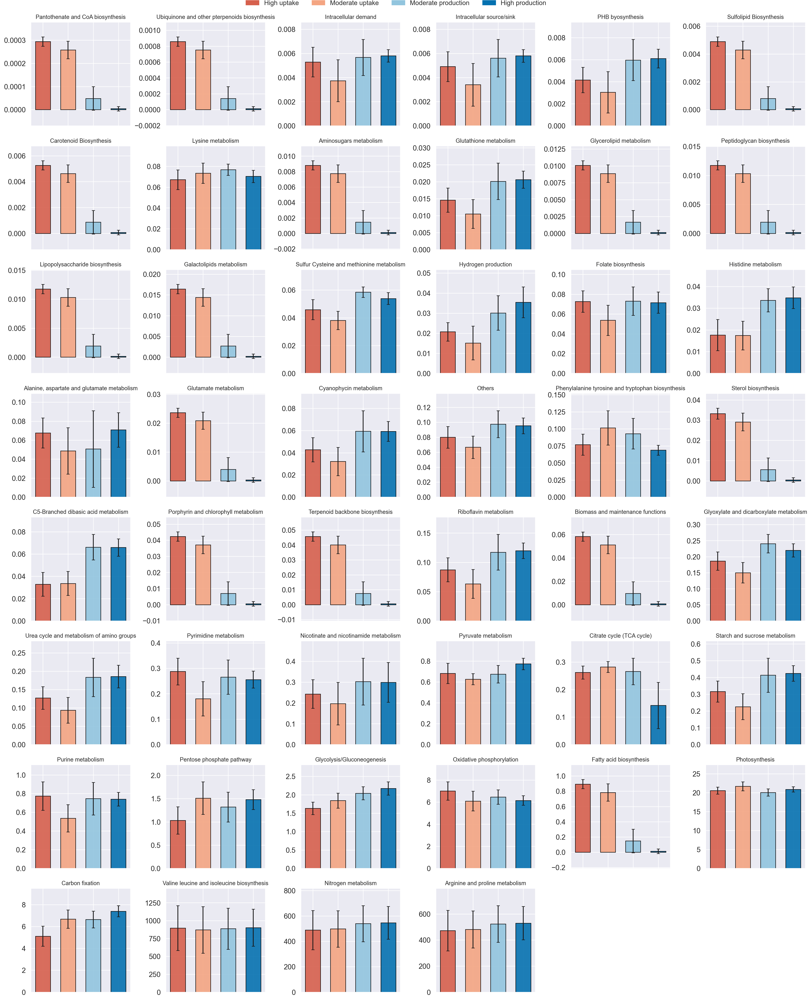

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cobra
import os

# -----------------------------
# Load data
# -----------------------------
means2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS/std_sampling_exchange_stds.dat',
    sep='\t'
)

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')

indexes = []
for file in os.listdir('results_new/genome_scale_samples_PEAKS/'):
    if 'cell' in file: 
        i = int(file.split('cell')[-1].split('.')[0])
        indexes.append(i)
indexes = sorted(indexes)

means_toy = means_toy.loc[indexes]
stds_toy = stds_toy.loc[indexes]
means2.index=indexes
stds2.index=indexes



df = means_toy  # replace with your actual df

# split by sign
df_pos = df[df["ac"] > 0].copy()
df_neg = df[df["ac"] < 0].copy()

# define thresholds (within each group)
pos_thresh = df_pos["ac"].median()
neg_thresh = df_neg["ac"].median()

df_pos_2 = means2[df["ac"] > 0].copy()
df_neg_2 = means2[df["ac"] < 0].copy()

# positive groups
df_pos_low = df_pos_2[df_pos["ac"] <= pos_thresh]   # moderate positive
df_pos_high = df_pos_2[df_pos["ac"] > pos_thresh]   # high positive

# negative groups
df_neg_low = df_neg_2[df_neg["ac"] >= neg_thresh]   # moderate negative (closer to 0)
df_neg_high = df_neg_2[df_neg["ac"] < neg_thresh]   # high negative (more extreme)

groups = {
    "pos_high": df_pos_high,
    "pos_moderate": df_pos_low,
    "neg_moderate": df_neg_low,
    "neg_high": df_neg_high
}



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cobra


# =========================================================
# LOAD MODEL + PATHWAYS
# =========================================================
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

excluded = ['Transport', 'Extracellular exchange']

subsystems = sorted(set(
    r.subsystem for r in model.reactions
    if r.subsystem and r.subsystem not in excluded
))

# =========================================================
# PATHWAY FLUX PER SAMPLE
# =========================================================
def pathway_flux_per_sample(df):
    flux_dict = {}

    for s in subsystems:
        cols = [
            r.id for r in model.reactions
            if r.subsystem == s and r.id in df.columns
        ]

        if len(cols) == 0:
            continue

        flux_dict[s] = df[cols].sum(axis=1).values

    return flux_dict

# compute all groups
group_flux = {
    name: pathway_flux_per_sample(gdf)
    for name, gdf in groups.items()
}

# =========================================================
# RANK PATHWAYS BY DIFFERENCE ACROSS 4 GROUPS
# =========================================================
scores = []

for s in subsystems:
    vals = []

    for g in groups.keys():
        if s in group_flux[g]:
            vals.append(np.mean(group_flux[g][s]))
        else:
            vals.append(0)

    score = np.std(vals)  # separation across groups
    scores.append([s, score])

stats_df = pd.DataFrame(scores, columns=["pathway", "score"])
stats_df = stats_df.sort_values("score", ascending=True).head(100)

top_paths = stats_df["pathway"].values

top_paths = top_paths[7:]
# =========================================================
# PLOT SETTINGS
# =========================================================
colors = {
    "pos_moderate": "#f4a582",
    "pos_high": "#d6604d",
    "neg_moderate": "#92c5de",
    "neg_high": "#0571b0"
}

ncols = 6
nrows = math.ceil(len(top_paths) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(3.5 * ncols, 3.2 * nrows),
    dpi=200
)

axes = np.array(axes).flatten()

# =========================================================
# PLOT
# =========================================================
for ax, p in zip(axes, top_paths):

    means = []
    stds = []

    for gname, gdf in groups.items():
        if p in group_flux[gname]:
            vals = group_flux[gname][p]
        else:
            vals = np.array([0])

        means.append(abs(np.mean(vals)))
        stds.append(np.std(vals))
        

    x = np.arange(4)

    ax.bar(
        x,
        means,
        yerr=stds,
        capsize=3,
        width=0.6,
        edgecolor="black",
        color=[colors[g] for g in groups.keys()],
        alpha=0.9
    )

    ax.set_xticks(x)
    ax.set_xticklabels([], rotation=45, fontsize=7)
    ax.set_title(p, fontsize=10.5)

    # independent y-axis scaling
    ax.margins(y=0.2)

from matplotlib.patches import Patch
    
legend_handles = [
    Patch(color=colors["pos_high"], label="High uptake"),
    Patch(color=colors["pos_moderate"], label="Moderate uptake"),
    Patch(color=colors["neg_moderate"], label="Moderate production"),
    Patch(color=colors["neg_high"], label="High production"),
]

fig.legend(
    handles=legend_handles,
    loc=(0.3, 0.991),
    ncol=4,
    frameon=False,
    fontsize=12, 
)
# remove empty panels
for ax in axes[len(top_paths):]:
    ax.remove()

plt.tight_layout()
plt.show()

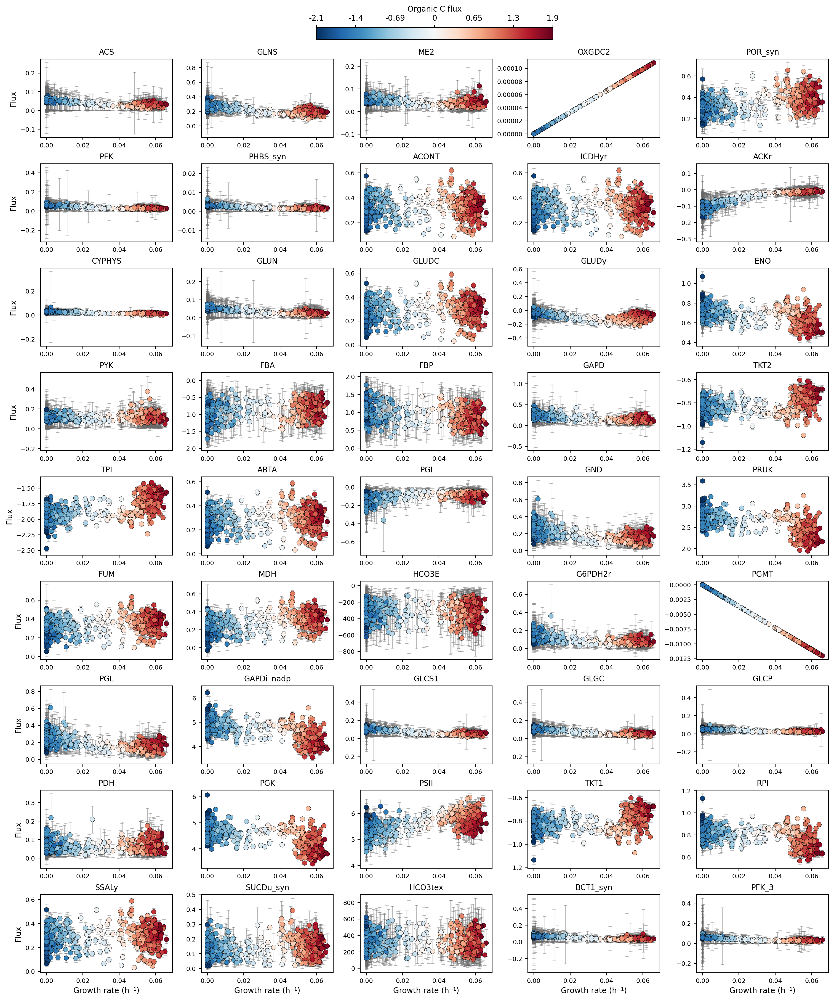

In [6]:
import math
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


df_template = pd.read_csv('results/metabolic_maps/template.csv', sep=',')


reactions = (
    df_template.loc[
        ~df_template['reaction'].str.lower().str.contains('biomass', na=False),
        'reaction'
    ]
    .drop_duplicates()
    .tolist()
)

reactions_main = [
#    "PHBS_syn",
    "RBPC",
    "RBCh",
    "CS",
    "PGM",
    "RPE",
    "PTAr",
    "EX_glu__L_e",
    "ATPSu",
#    "GLCP",
#    "CYPHYS", 
    "PPS",
    "PPC", 
    "EX_ac_e"
]
reactions = [r for r in reactions if r not in reactions_main]
n=len(reactions)

# choose grid dimensions
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3*ncols, 2*nrows),
    dpi=200,
    constrained_layout=True
)

#fig.subplots_adjust(
#    wspace=0.2,   # horizontal spacing (smaller = tighter)
#    hspace=0.3   # vertical spacing
#)

axes = np.array(axes).flatten()

values = means_toy['ac']

vmin = np.min(values)
vmax = np.max(values)
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)





for ax, r in zip(axes, reactions):    
    if r == 'EX_ac_e':
        factor = -1
    else:
        factor = 1
    # error bars
    ax.errorbar(
        means2['BIOMASS_Ec_SynMixo'],
        factor*means2[r],
        xerr=stds2['BIOMASS_Ec_SynMixo'],
        yerr=stds2[r],
        fmt='none',
        ecolor='dimgrey',
        elinewidth=0.5,
        capsize=2,
        alpha=0.5,
        zorder=1
    )

    # scatter
    sc = ax.scatter(
        means2['BIOMASS_Ec_SynMixo'],
        factor*means2[r],
        c=values,
        cmap='RdBu_r',
        norm=norm,
        s=40,
        edgecolor='black',
        linewidth=0.3,
        zorder=2
    )

    ax.set_title(r, fontsize=10)
    ax.tick_params(labelsize=8)

    # only show outer labels
    if ax in axes[-ncols:]:
        ax.set_xlabel('Growth rate (h⁻¹)', fontsize=10)

    if ax in axes[::ncols]:
        ax.set_ylabel('Flux', fontsize=10)

# remove unused panels
for ax in axes[len(reactions):]:
    ax.remove()

    
## one colorbar for the entire figure
cbar = fig.colorbar(
    sc,
    ax=axes[:len(reactions)],
    shrink=0.3,
    pad=0.01, orientation = 'horizontal', location = 'top', fraction = 0.1
)
cbar.set_label('Organic C flux')

neg_ticks = np.linspace(vmin, 0, 4)   # negative arm
pos_ticks = np.linspace(0, vmax, 4)    # positive arm

ticks = np.unique(np.concatenate([neg_ticks, pos_ticks]))

cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t:.2g}" for t in ticks])


plt.show()

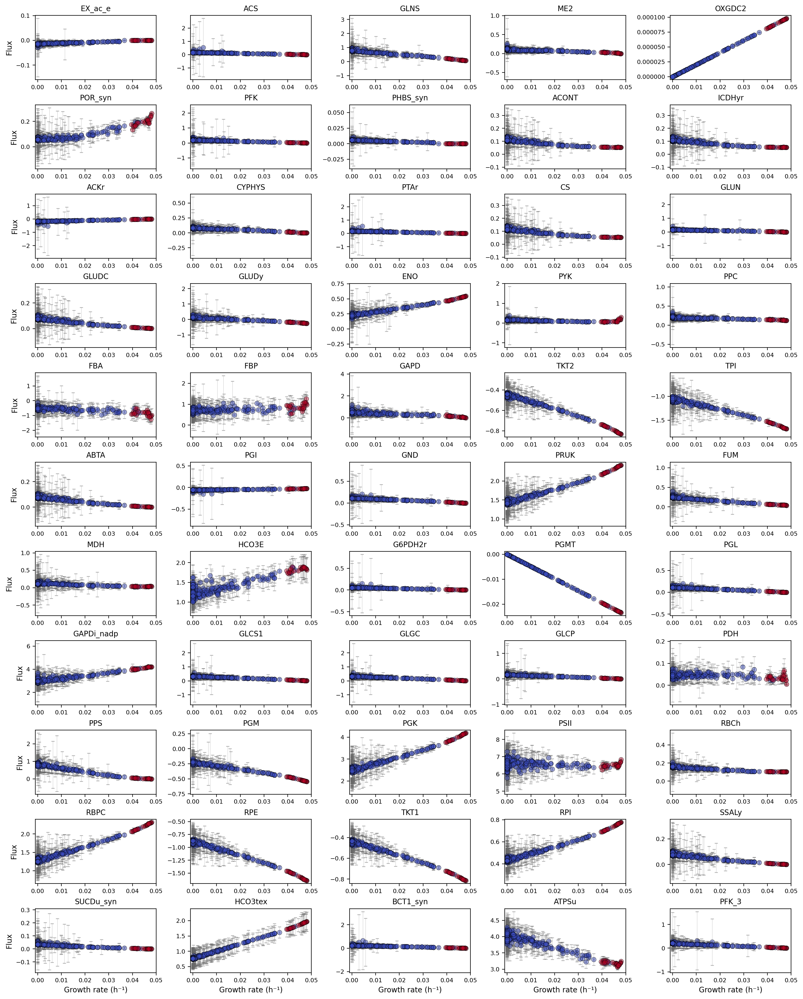

In [14]:
import math
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


df_template = pd.read_csv('results/metabolic_maps/template.csv', sep=',')


reactions = (
    df_template.loc[
        ~df_template['reaction'].str.lower().str.contains('biomass', na=False),
        'reaction'
    ]
    .drop_duplicates()
    .tolist()
)

means2 = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds2 = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat',
    sep='\t'
)


indexes = []
files = os.listdir('results_new/genome_scale_samples_no_exchange_PEAKS/')
for f in files: 
    if 'cell' in f: 
        index = int(f.split('cell')[-1].split('.dat')[0])
        indexes.append(index)

indexes = sorted(indexes)
clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
clusters = clusters.loc[indexes]
clusters.index = means2.index

cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]

n=len(reactions)

# choose grid dimensions
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3*ncols, 1.7*nrows),
    dpi=200,
    constrained_layout=True
)

#fig.subplots_adjust(
#    wspace=0.2,   # horizontal spacing (smaller = tighter)
#    hspace=0.3   # vertical spacing
#)

axes = np.array(axes).flatten()

values = means2['BIOMASS_Ec_SynAuto']

color12 = (0.0, 0.5, 0.5, 0.35)     # teal (fill)


for ax, r in zip(axes, reactions):    
    if r == 'EX_ac_e' or r =='HCO3Etex' or r =='HCO3E':
        factor = -1
    else:
        factor = 1
    
    if r != 'HCO3E' and r!= 'HCO3tex':
        for j in [0,1]:

            # error bars
            ax.errorbar(
                means2[clusters['cluster']==j]['BIOMASS_Ec_SynAuto'],
                factor*means2[clusters['cluster']==j][r],
                xerr=stds2[clusters['cluster']==j]['BIOMASS_Ec_SynAuto'],
                yerr=stds2[clusters['cluster']==j][r],
                fmt='none',
                ecolor='dimgrey',
                elinewidth=0.3,
                capsize=2,
                alpha=0.5,
                zorder=1
            )
    
        # scatter
            sc = ax.scatter(
                means2[clusters['cluster']==j]['BIOMASS_Ec_SynAuto'],
                factor*means2[clusters['cluster']==j][r],
                color=colors[j],
                s=40,
                edgecolor='black',
                linewidth=0.3,
                zorder=2
            )
        
    else:
        # error bars
        for j in [0,1]:
            ax.errorbar(
                means2[clusters['cluster']==j]['BIOMASS_Ec_SynAuto'],
                factor*means2[clusters['cluster']==j][r]-means2[clusters['cluster']==j]['EX_co2_e'],
                xerr=stds2[clusters['cluster']==j]['BIOMASS_Ec_SynAuto'],
                yerr=stds2[clusters['cluster']==j][r]/800,
                fmt='none',
                ecolor='dimgrey',
                elinewidth=0.3,
                capsize=2,
                alpha=0.5,
                zorder=1
            )
        
            # scatter
            sc = ax.scatter(
                means2[clusters['cluster']==j]['BIOMASS_Ec_SynAuto'],
                factor*means2[clusters['cluster']==j][r]-means2[clusters['cluster']==j]['EX_co2_e'],
                color=colors[j],
                s=40,
                edgecolor='black',
                linewidth=0.3,
                zorder=2
            )
        
    ax.set_xlim(-0.001,0.05)
    ax.set_title(r, fontsize=10)
    ax.tick_params(labelsize=8)

    # only show outer labels
    if ax in axes[-ncols:]:
        ax.set_xlabel('Growth rate (h⁻¹)', fontsize=10)

    if ax in axes[::ncols]:
        ax.set_ylabel('Flux', fontsize=10)
# remove unused panels
for ax in axes[len(reactions):]:
    ax.remove()


plt.savefig('fluxes_no_exchange.png', format='png', dpi=200, bbox_inches='tight')

plt.show()

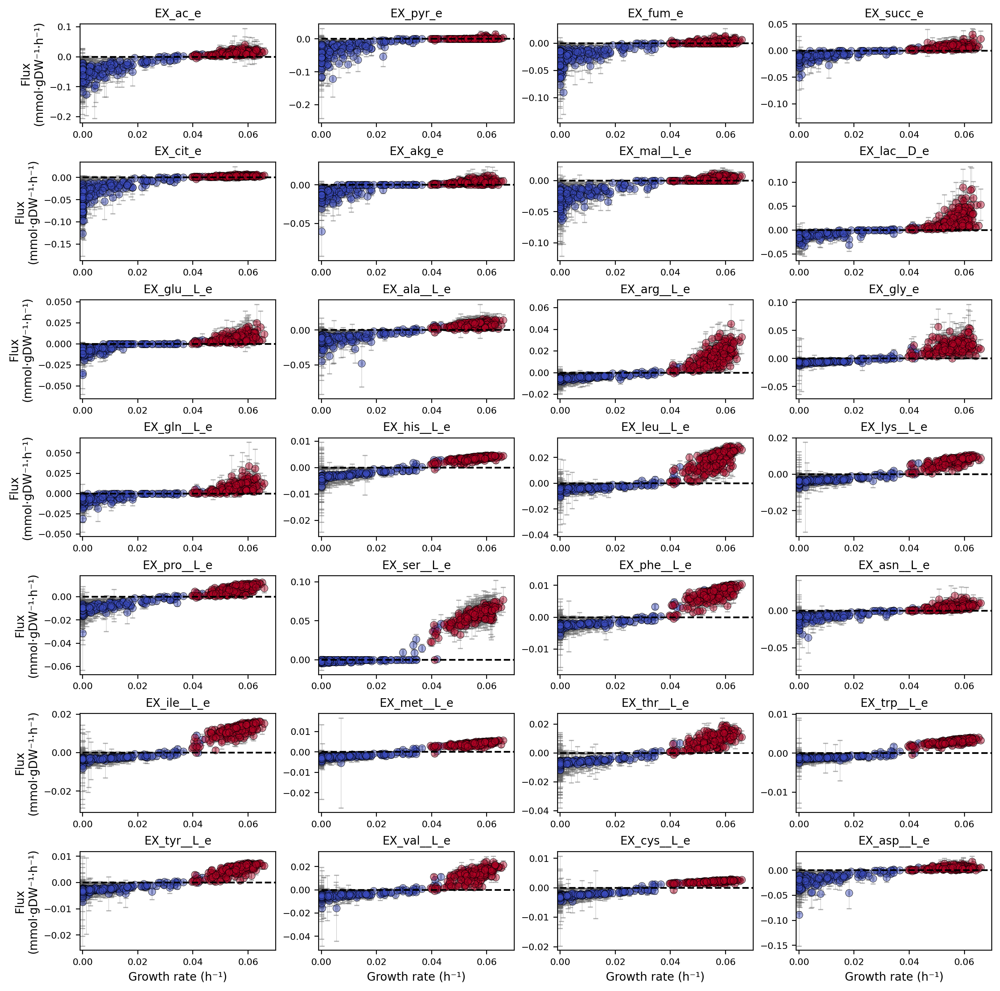

In [30]:
import math
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm



means2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat', index_col=0,
    sep='\t'
)

stds2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat', index_col=0,
    sep='\t'
)


clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
clusters = clusters.loc[means2.index]
#clusters.index = means2.index


#model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')
#
acids_set = ['EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e', 'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e', 'EX_lac__D_e']
#acids_c = [model.reactions.get_by_id(r).reactants[0].elements['C'] for r in acids_set]
#   
#    
aminoacids = ['glu__L', 'ala__L', 'arg__L', 'gly', 'gln__L', 'his__L', 'leu__L','lys__L', 'pro__L', 'ser__L', 
             'phe__L', 'asn__L', 'ile__L', 'met__L', 'thr__L', 'trp__L', 'tyr__L', 'val__L', 'cys__L', 'asp__L']



cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]


reactions = acids_set

for a in aminoacids:
    reactions.append('EX_'+a+'_e')

#reactions = [r for r in reactions if r not in reactions_main]
n=len(reactions)

# choose grid dimensions
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3*ncols, 1.7*nrows),
    dpi=200,
    constrained_layout=True
)

#fig.subplots_adjust(
#    wspace=0.2,   # horizontal spacing (smaller = tighter)
#    hspace=0.3   # vertical spacing
#)

axes = np.array(axes).flatten()

values = means2['BIOMASS_Ec_SynMixo']

color12 = (0.0, 0.5, 0.5, 0.35)     # teal (fill)


for ax, r in zip(axes, reactions):    
    factor = -1

    for j in [0,1]:
        # error bars
        ax.errorbar(
            means2[clusters['cluster']==j]['BIOMASS_Ec_SynMixo'],
            factor*means2[clusters['cluster']==j][r],
            xerr=stds2[clusters['cluster']==j]['BIOMASS_Ec_SynMixo'],
            yerr=stds2[clusters['cluster']==j][r],
            fmt='none',
            ecolor='dimgrey',
            elinewidth=0.3,
            capsize=2,
            alpha=0.5,
            zorder=1
        )
    
        # scatter
        ax.scatter(
            means2[clusters['cluster']==j]['BIOMASS_Ec_SynMixo'],
            factor*means2[clusters['cluster']==j][r],
            color=colors[j],
            s=40,
            edgecolor='black',
            linewidth=0.3,
            zorder=2
        )
        

    ax.plot([0,0.18], [0,0], color='black', linestyle='dashed')
    ax.set_xlim(-0.001,0.07)
    ax.set_title(r, fontsize=10)
    ax.tick_params(labelsize=8)

    # only show outer labels
    if ax in axes[-ncols:]:
        ax.set_xlabel('Growth rate (h⁻¹)', fontsize=10)

    if ax in axes[::ncols]:
        ax.set_ylabel('Flux\n(mmol·gDW⁻¹·h⁻¹)', fontsize=10)
        
# remove unused panels
for ax in axes[len(reactions):]:
    ax.remove()


plt.savefig('Organic_C_exchange.png', format='png', dpi=200, bbox_inches='tight')
plt.show()